# 🚀 Notebook 02 — Baseline: TF-IDF + Logistic Regression

Goal: the first **end-to-end loop** — train, validate properly, predict on the test set, and submit to Kaggle.

Pipeline:

```
clean text -> train/val split -> TF-IDF (word 1-2 grams)
    -> one LogisticRegression per label (6 binary classifiers)
    -> per-class AUC on the validation set
    -> refit on FULL train -> predict test -> submit
```

Why this is the right first model:
- EDA showed the vocabulary is highly distinctive (bigrams literally expose the classes) — bag-of-words models are *strong* here.
- 6 independent binary classifiers is a legitimate multi-label strategy (we know from EDA the labels overlap; shared-representation models come later).
- It trains in minutes on CPU, giving us a fast, honest baseline: every fancier model must beat this number.

## 1. Setup & data

In [1]:
import re
import time
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

sns.set_theme(style='whitegrid', context='talk')
print('ready')

ready


In [2]:
def find_project_root(marker='data'):
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / marker).is_dir():
            return p
    raise FileNotFoundError(f"No '{marker}/' found above {Path.cwd()}")

ROOT = find_project_root()
DATA_DIR, SUB_DIR = ROOT / 'data', ROOT / 'submissions'
FIG_DIR = ROOT / 'figures'
SUB_DIR.mkdir(exist_ok=True)

LABELS = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
PRETTY = {'toxic': 'Toxic', 'severe_toxic': 'Severe toxic', 'obscene': 'Obscene',
          'threat': 'Threat', 'insult': 'Insult', 'identity_hate': 'Identity hate'}
C_MAIN = '#55A868'

train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
print(f'train: {train.shape}   test: {test.shape}')
print(f'test missing comment_text: {int(test["comment_text"].isna().sum())}')

# Exact duplicate comments (EDA showed copy-paste spam) - knowing the count
# matters for how much we trust a random train/val split (see notes below).
print(f'exact duplicate comments in train: {int(train["comment_text"].duplicated().sum())}')

train: (159571, 8)   test: (153164, 2)
test missing comment_text: 0
exact duplicate comments in train: 0


## 2. Light text cleaning

For a TF-IDF baseline, **less is more**: sklearn's tokenizer already lowercases and strips punctuation. Two Wikipedia-specific artifacts are worth removing though:
- **URLs** — talk pages are full of links; they'd become noise tokens.
- **IP addresses** — anonymous editors are identified by their IP (e.g. `162.54.3.4`); these are high-cardinality junk features.

Deliberately NOT doing yet (each is its own experiment later): stemming/lemmatization, emoji handling, stopword removal (harmful for TF-IDF+linear!), expansion of contractions.

In [3]:
URL_RE = re.compile(r'https?://\S+|www\.\S+')
IP_RE = re.compile(r'\b\d{1,3}(?:\.\d{1,3}){3}\b')

def clean(text):
    text = URL_RE.sub(' ', str(text))
    text = IP_RE.sub(' ', text)
    return text

train['clean'] = train['comment_text'].fillna('').map(clean)
test['clean'] = test['comment_text'].fillna('').map(clean)

changed = int((train['clean'] != train['comment_text'].fillna('').astype(str)).sum())
print(f'train comments changed by cleaning: {changed:,}')

example = train.loc[train['comment_text'].str.contains('http', na=False), 'comment_text'].iloc[0]
print('\nBEFORE:', example[:150])
print('AFTER :', clean(example)[:150])

train comments changed by cleaning: 14,340

BEFORE: "

 Snowflakes are NOT always symmetrical! 

Under Geometry it is stated that ""A snowflake always has six symmetric arms."" This assertion is simply 
AFTER : "

 Snowflakes are NOT always symmetrical! 

Under Geometry it is stated that ""A snowflake always has six symmetric arms."" This assertion is simply 


## 3. Train / validation split

Single 80/20 split with a fixed seed. **Honesty rules:**
- The vectorizer is fit on the *training part only* — fitting it on everything would leak test vocabulary into validation (classic leakage bug).
- Known caveat from EDA: copy-paste spam means some near-identical comments land on both sides, making validation slightly optimistic. Proper de-duplicated cross-validation comes in notebook 03.

In [4]:
Y = train[LABELS].values
X_tr, X_val, Y_tr, Y_val = train_test_split(
    train['clean'].values, Y, test_size=0.2, random_state=42)

print(f'train: {len(X_tr):,}   val: {len(X_val):,}')
val_pos = pd.Series(Y_val.sum(axis=0), index=LABELS, name='positives in val')
val_pos.to_frame().T

train: 127,656   val: 31,915


,toxic,severe_toxic,obscene,threat,insult,identity_hate
positives in val,3056,321,1715,74,1614,294


Note how few validation positives the rare labels get — `threat` has only ~96. That means per-class AUC on the val split is *noisy* for rare classes; expect them to move a lot between runs.

## 4. TF-IDF vectorization

Hyperparameter choices and why:
- `ngram_range=(1, 2)` — EDA showed bigrams carry the signal ('piece of', 'fuck fuck'); unigrams alone would lose phrases.
- `min_df=3` — drop hapax/typos seen <3 times (noise reduction, smaller matrix).
- `sublinear_tf=True` — log-scaling term frequency: saying a swear word 10 times is not 10× more informative than once.
- NO stopword removal — for linear models, 'you are a ...' function words actually help calibrate scores.
- `max_features=200000` — hard cap; the 1-2 gram vocabulary would otherwise be huge.

In [5]:
t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=200000,
                        sublinear_tf=True)
Xtr_t = tfidf.fit_transform(X_tr)   # fit ONLY on the training part
Xval_t = tfidf.transform(X_val)     # transform only
print(f'vectorized in {time.time() - t0:.1f}s')
print(f'matrix: {Xtr_t.shape[0]:,} docs x {Xtr_t.shape[1]:,} features, '
      f'sparsity {1 - Xtr_t.nnz / (Xtr_t.shape[0] * Xtr_t.shape[1]):.2%}')

# a peek at the learned vocabulary
sample = list(tfidf.vocabulary_.items())[:10]
print('vocab sample:', [w for w, _ in sample])

vectorized in 38.6s
matrix: 127,656 docs x 200,000 features, sparsity 99.96%
vocab sample: ['grandma', 'terri', 'should', 'burn', 'in', 'trash', 'is', 'hate', 'her', 'to']


## 5. Train one logistic regression per label

Six independent binary classifiers (`C=1.0`, `class_weight='balanced'` helps the rare classes). Metric: **ROC AUC per class** — threshold-free, matching the competition's metric (mean column-wise AUC). We report each class AUC alongside how many positives it has in val, because a 0.99 on 20k positives and a 0.90 on 96 positives are very different claims.

In [6]:
aucs = {}
for i, label in enumerate(LABELS):
    clf = LogisticRegression(C=1.0, class_weight='balanced',
                             solver='liblinear', max_iter=1000)
    t0 = time.time()
    clf.fit(Xtr_t, Y_tr[:, i])
    proba = clf.predict_proba(Xval_t)[:, 1]
    aucs[label] = roc_auc_score(Y_val[:, i], proba)
    print(f'{label:14s} val AUC = {aucs[label]:.4f}   '
          f'({int(Y_val[:, i].sum()):4d} val positives, fit {time.time() - t0:4.1f}s)')

mean_auc = float(np.mean(list(aucs.values())))
print(f'\nMEAN val AUC  = {mean_auc:.4f}   <- the number to beat')

toxic          val AUC = 0.9734   (3056 val positives, fit 15.2s)


severe_toxic   val AUC = 0.9830   ( 321 val positives, fit 12.3s)


obscene        val AUC = 0.9865   (1715 val positives, fit  9.4s)


threat         val AUC = 0.9907   (  74 val positives, fit  9.5s)


insult         val AUC = 0.9802   (1614 val positives, fit  9.5s)


identity_hate  val AUC = 0.9733   ( 294 val positives, fit 10.3s)

MEAN val AUC  = 0.9812   <- the number to beat


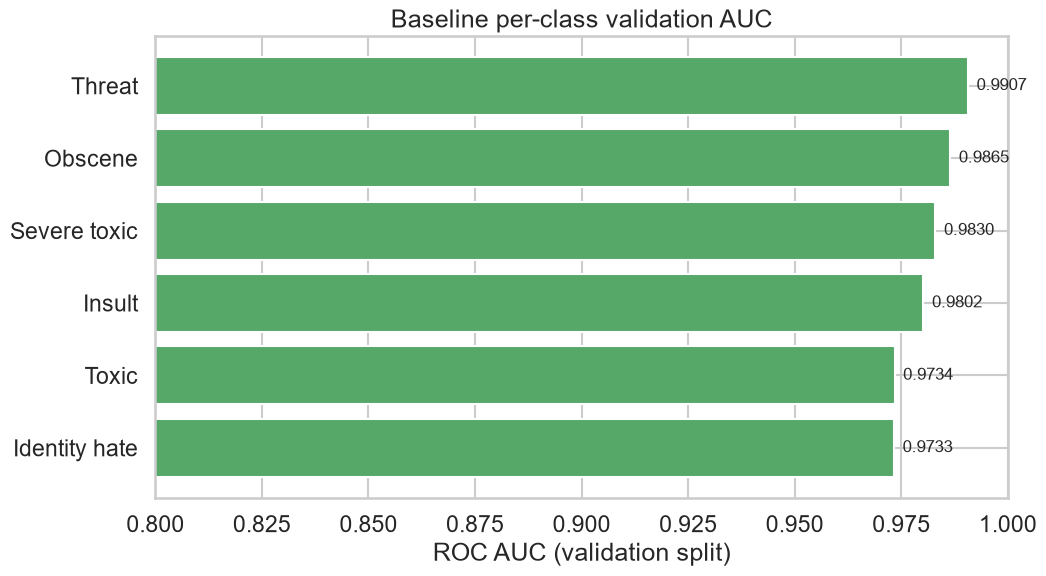

In [7]:
fig, ax = plt.subplots(figsize=(11, 6))
items = sorted(aucs.items(), key=lambda kv: kv[1])
ax.barh([PRETTY[k] for k, _ in items], [v for _, v in items], color=C_MAIN)
for i, (k, v) in enumerate(items):
    ax.text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=12)
ax.set_xlim(0.8, 1.0)
ax.set_title('Baseline per-class validation AUC')
ax.set_xlabel('ROC AUC (validation split)')
fig.savefig(FIG_DIR / '08_baseline_per_class_auc.png', dpi=140, bbox_inches='tight')
plt.show()

Typical pattern: `toxic`/`obscene`/`insult` score highest (most data + distinctive vocabulary), `severe_toxic` does fine despite few examples (extreme language is easy), and `threat`/`identity_hate` wobble — tiny val supports. If `threat` AUC looks high anyway, remember: with ~96 positives a lucky split can inflate it.

## 6. Refit on the full training set & predict the test set

Validation told us the approach works. For the actual submission we want every scrap of labeled data, so: refit vectorizer + 6 classifiers on **all 159,571 rows**, predict probabilities for test, and write `submission.csv`.

In [8]:
t0 = time.time()
tfidf_full = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=200000,
                             sublinear_tf=True)
Xall_t = tfidf_full.fit_transform(train['clean'].values)
Xtest_t = tfidf_full.transform(test['clean'].values)
print(f're-vectorized in {time.time() - t0:.1f}s: {Xall_t.shape}')

sub = pd.DataFrame({'id': test['id']})
Y_all = train[LABELS].values
for i, label in enumerate(LABELS):
    t0 = time.time()
    clf = LogisticRegression(C=1.0, class_weight='balanced',
                             solver='liblinear', max_iter=1000)
    clf.fit(Xall_t, Y_all[:, i])
    sub[label] = clf.predict_proba(Xtest_t)[:, 1]
    print(f'  {label:14s} refit+predict {time.time() - t0:4.1f}s')

assert sub[LABELS].isin([0, 1]).sum().sum() == 0  # real probabilities, not 0/1
print('\nsanity: probabilities in range',
      float(sub[LABELS].values.min()), '->', float(sub[LABELS].values.max()))

re-vectorized in 45.8s: (159571, 200000)


  toxic          refit+predict 14.2s


  severe_toxic   refit+predict 14.1s


  obscene        refit+predict 13.3s


  threat         refit+predict 13.9s


  insult         refit+predict 13.8s


  identity_hate  refit+predict 14.9s

sanity: probabilities in range 0.00013612688749717604 -> 0.9999999999999998


In [9]:
SUB_PATH = SUB_DIR / 'submission_01_tfidf_logreg.csv'
sub.to_csv(SUB_PATH, index=False)
print(f'wrote {SUB_PATH}  ({SUB_PATH.stat().st_size / 1024 / 1024:.1f} MB)')
sub.head()

wrote C:\Users\djame\Downloads\NLP\Jiggsaw\submissions\submission_01_tfidf_logreg.csv  (20.4 MB)


,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,00001cee341fdb12,0.999762,0.911444,0.999764,0.634291,0.995180,0.953725
1,0000247867823ef7,0.023867,0.010796,0.009420,0.002394,0.027783,0.017039
2,00013b17ad220c46,0.073953,0.014591,0.048868,0.006252,0.049139,0.019117
3,00017563c3f7919a,0.013451,0.014776,0.011268,0.006905,0.010756,0.008193
4,00017695ad8997eb,0.099011,0.032738,0.050585,0.009772,0.032542,0.014374


## 7. Submit to Kaggle via the API

The competition has ended, so this is a **late submission** — no team/entries impact; Kaggle still scores it against the held-out test labels and shows it on the leaderboard. Perfect for learning. The CLI call is the same one you'd use from any script:

```
kaggle competitions submit -c jigsaw-toxic-comment-classification-challenge -f <file> -m "message"
```

In [10]:
r = subprocess.run(
    ['python', '-m', 'kaggle', 'competitions', 'submit',
     '-c', 'jigsaw-toxic-comment-classification-challenge',
     '-f', str(SUB_PATH),
     '-m', 'nb02 baseline: tfidf word(1-2) min_df=3 + logreg C=1 balanced'],
    capture_output=True, text=True, timeout=300)
print(r.stdout[-800:])
if r.returncode != 0:
    print('STDERR:', r.stderr[-800:])

Submission ref: 58622163
99 submissions remaining today.
Successfully submitted to Toxic Comment Classification Challenge


In [11]:
# Scoring takes ~1 minute. Re-run this cell if the status says 'pending'.
r = subprocess.run(
    ['python', '-m', 'kaggle', 'competitions', 'submissions',
     '-c', 'jigsaw-toxic-comment-classification-challenge'],
    capture_output=True, text=True, timeout=120)
print(r.stdout[:1500])

     ref  fileName                        date                        description                                                    status                     publicScore  privateScore  
--------  ------------------------------  --------------------------  -------------------------------------------------------------  -------------------------  -----------  ------------  
58622163  submission_01_tfidf_logreg.csv  2026-11-20 16:29:59.593000  nb02 baseline: tfidf word(1-2) min_df=3 + logreg C=1 balanced  SubmissionStatus.COMPLETE  0.97550      0.97577       



## 8. Takeaways

1. **The loop is the point** — data -> features -> model -> metric -> submission. Everything later is a variation on it.
2. **TF-IDF + linear is shockingly strong** on toxicity data (expect ~0.96-0.97 mean AUC) because the classes are vocabulary-driven.
3. **Validation discipline**: vectorizer fit on train-only, single seed, honest caveat about duplicate leakage.
4. **Rare classes = noisy estimates** — `threat` val AUC has huge error bars with ~96 positives; don't tune hyperparameters against it.

**Next:** notebook 03 — evaluation deep-dive (de-duplicated cross-validation, threshold analysis, error inspection) and then notebook 04 — a fine-tuned transformer to see how far we can push the ceiling.